In [2]:
import pandas as pd

data=pd.read_csv("../data/customer-churn-clean.csv")

print(data.head())
print(data.shape)
print(data.columns.tolist())

x=data.drop(columns=["customerID","Churn"])
print(x.columns.tolist())
y=data["Churn"]


print(data["Churn"].value_counts())

print(data["Churn"].value_counts(normalize=True) * 100)


# print(data.isna().sum())


   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
from sklearn.model_selection import train_test_split


y = data["Churn"].str.strip().str.lower().map({
    "no": 0,
    "yes": 1
})

X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)


print(y.value_counts())
print("-----train-----")
print(y_train.value_counts())#train
print("-----test-----")
print(y_test.value_counts())#test



Churn
0    5174
1    1869
Name: count, dtype: int64
-----train-----
Churn
0    4139
1    1495
Name: count, dtype: int64
-----test-----
Churn
0    1035
1     374
Name: count, dtype: int64


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# separer data

numeric_data=x.select_dtypes(
    include=["int64","float64"]
).columns.tolist()

categorie_data=x.select_dtypes(
    include=["object"]
).columns.tolist()


print(numeric_data)
print(" ------ ")
print(categorie_data)


numeric_pipline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_pipline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer([
    ("numeric",numeric_pipline,numeric_data),
    ("categorical",categorical_pipline,categorie_data)
])


['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
 ------ 
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\youco\AppData\Local\Temp\ipykernel_19852\2114091162.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorie_data=x.select_dtypes(


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score) 

Logistic_pip=Pipeline([
    ("preprocessing",preprocessor),
    ("model",LogisticRegression(class_weight="balanced",random_state=42,max_iter=1000))
])

Logistic_pip.fit(X_train,y_train)

y_pred=Logistic_pip.predict(X_test)

print(y_pred[:20])

# evaluation du modele
print("Accuracy : ",accuracy_score(y_test,y_pred))
print("Precision : ",precision_score(y_test,y_pred))
print("Recall : ",recall_score(y_test,y_pred))
print("F1-score : ",f1_score(y_test,y_pred))

print(confusion_matrix(y_test,y_pred))

y_proba_logistic = Logistic_pip.predict_proba(X_test)[:, 1]

[0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 0 0]
Accuracy :  0.7381121362668559
Precision :  0.504302925989673
Recall :  0.7834224598930482
F1-score :  0.6136125654450262
[[747 288]
 [ 81 293]]


In [6]:
# avec smoote
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

Logistic_pip_smote=Pipeline([
    ("preprocessing",preprocessor),
    ("smote",SMOTE(random_state=42)),
    ("model",LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

Logistic_pip_smote.fit(X_train,y_train)
Logistic_smote_predict=Logistic_pip_smote.predict(X_test)

print(Logistic_smote_predict[:20])


print("Accuracy avec smote:: ",accuracy_score(y_test,Logistic_smote_predict))
print("Precision avec smote: : ",precision_score(y_test,Logistic_smote_predict))
print("Recall avec smote:: ",recall_score(y_test,Logistic_smote_predict))
print("F1-score avec smote:: ",f1_score(y_test,Logistic_smote_predict))

print(confusion_matrix(y_test,Logistic_smote_predict))

[0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 0 0]
Accuracy avec smote::  0.7374024130589071
Precision avec smote: :  0.5033898305084745
Recall avec smote::  0.7941176470588235
F1-score avec smote::  0.6161825726141079
[[742 293]
 [ 77 297]]


In [7]:
from sklearn.tree import DecisionTreeClassifier

tree_model=Pipeline([
    ("preprocessing",preprocessor),
    ("model",DecisionTreeClassifier(class_weight="balanced",random_state=42))
])

tree_model.fit(X_train,y_train)

y_pred_tree=tree_model.predict(X_test)
print(y_pred_tree[:20])


# evaluation 
print("Accuracy : ",accuracy_score(y_test,y_pred_tree))
print("precision : ",precision_score(y_test,y_pred_tree))
print("recall : ",recall_score(y_test,y_pred_tree))
print("f1_score : " ,f1_score(y_test,y_pred_tree))
print(confusion_matrix(y_test,y_pred_tree))

y_proba_tree = tree_model.predict_proba(X_test)[:, 1]

[0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0]
Accuracy :  0.7430801987224982
precision :  0.5167597765363129
recall :  0.4946524064171123
f1_score :  0.505464480874317
[[862 173]
 [189 185]]


In [8]:
# avec smoote
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

tree_model_smoote=Pipeline([
    ("preprocessing",preprocessor),
    ("smote",SMOTE(random_state=42)),
    ("model",DecisionTreeClassifier(random_state=42))
])

tree_model_smoote.fit(X_train,y_train)

tree_mode_smote_predict=tree_model_smoote.predict(X_test)

print(tree_mode_smote_predict[:20])


print("Accuracy avec smote:: ",accuracy_score(y_test,tree_mode_smote_predict))
print("Precision avec smote: : ",precision_score(y_test,tree_mode_smote_predict))
print("Recall avec smote:: ",recall_score(y_test,tree_mode_smote_predict))
print("F1-score avec smote:: ",f1_score(y_test,tree_mode_smote_predict))

print(confusion_matrix(y_test,tree_mode_smote_predict))

[0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0]
Accuracy avec smote::  0.7196593328601846
Precision avec smote: :  0.4752941176470588
Recall avec smote::  0.5401069518716578
F1-score avec smote::  0.5056320400500626
[[812 223]
 [172 202]]


In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_model=Pipeline([
    ("preprocessing",preprocessor),
    ("model",RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=42))
])

rf_model.fit(X_train,y_train)

pred_rf=rf_model.predict(X_test)
print(pred_rf[:20])

print("Accuracy : ",accuracy_score(y_test,pred_rf))
print("precision : " ,precision_score(y_test,pred_rf))
print("recall : " ,recall_score(y_test,pred_rf))
print("f1 : " ,f1_score(y_test,pred_rf))
print(confusion_matrix(y_test,pred_rf))

y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

[0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0]
Accuracy :  0.7700496806245565
precision :  0.5589622641509434
recall :  0.6336898395721925
f1 :  0.5939849624060151
[[848 187]
 [137 237]]


In [10]:
from imblearn.pipeline import Pipeline
pip_rf_smote=Pipeline([
    ("preprocessing",preprocessor),
    ("smote",SMOTE(random_state=42)),
    ("model",RandomForestClassifier(n_estimators=200,random_state=42))
])

pip_rf_smote.fit(X_train,y_train)

predict_rf_smote=pip_rf_smote.predict(X_test)
print(predict_rf_smote[:20])

print("Accuracy avec smote:: ",accuracy_score(y_test,predict_rf_smote))
print("Precision avec smote: : ",precision_score(y_test,predict_rf_smote))
print("Recall avec smote:: ",recall_score(y_test,predict_rf_smote))
print("F1-score avec smote:: ",f1_score(y_test,predict_rf_smote))

print(confusion_matrix(y_test,predict_rf_smote))

[0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0]
Accuracy avec smote::  0.7743080198722498
Precision avec smote: :  0.5777777777777777
Recall avec smote::  0.5561497326203209
F1-score avec smote::  0.5667574931880109
[[883 152]
 [166 208]]


In [11]:
from sklearn.svm import SVC

svm_model=Pipeline([
    ("preprocessing",preprocessor),
    ("model",SVC(class_weight="balanced",probability=True,random_state=42))
])

svm_model.fit(X_train,y_train)

predict_svm=svm_model.predict(X_test)

print(predict_svm[:20])

print("Accuracy : ",accuracy_score(y_test,predict_svm))
print("precision : " ,precision_score(y_test,predict_svm))
print("recall : " ,recall_score(y_test,predict_svm))
print("f1 : " ,f1_score(y_test,predict_svm))
print(confusion_matrix(y_test,predict_svm))

y_proba_svm = svm_model.predict_proba(X_test)[:, 1]

c:\CustomerRisk\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


[0 1 0 1 0 1 1 0 0 1 0 0 0 1 0 0 0 1 0 0]
Accuracy :  0.7437899219304471
precision :  0.511504424778761
recall :  0.7727272727272727
f1 :  0.6155484558040468
[[759 276]
 [ 85 289]]


In [12]:
from imblearn.pipeline import Pipeline

svm_model_smote=Pipeline([
    ("preprocessing",preprocessor),
    ("smote",SMOTE(random_state=42)),
    ("model",SVC(probability=True,random_state=42))
])

svm_model_smote.fit(X_train,y_train)

predict_svm_smote=svm_model_smote.predict(X_test)

print(predict_svm[:20])

print("Accuracy avec smote: ",accuracy_score(y_test,predict_svm_smote))
print("precision avec smote: " ,precision_score(y_test,predict_svm_smote))
print("recall avec smote: " ,recall_score(y_test,predict_svm_smote))
print("f1 avec smote: " ,f1_score(y_test,predict_svm_smote))
print(confusion_matrix(y_test,predict_svm_smote))

c:\CustomerRisk\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


[0 1 0 1 0 1 1 0 0 1 0 0 0 1 0 0 0 1 0 0]
Accuracy avec smote:  0.7544357700496807
precision avec smote:  0.52734375
recall avec smote:  0.7219251336898396
f1 avec smote:  0.6094808126410836
[[793 242]
 [104 270]]


In [13]:
from xgboost import XGBRFClassifier


neg=(y_train == 0).sum()
pos=(y_train == 1).sum()

scale_pos_weight=neg/pos
print(scale_pos_weight)

model_xgb=Pipeline([
    ("preprocessing",preprocessor),
    ("model",XGBRFClassifier(n_estimators=200,learning_rate=0.05,
        max_depth=4,scale_pos_weight=scale_pos_weight,
        random_state=42
    ))
])

model_xgb.fit(X_train,y_train)

y_pred_xgb=model_xgb.predict(X_test)
print(y_pred_xgb[:20])

print("Accuracy : ",accuracy_score(y_test,y_pred_xgb))
print("precision : " ,precision_score(y_test,y_pred_xgb))
print("recall : " ,recall_score(y_test,y_pred_xgb))
print("f1 : " ,f1_score(y_test,y_pred_xgb))
print(confusion_matrix(y_test,y_pred_xgb))

y_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]


2.768561872909699


c:\CustomerRisk\venv\Lib\site-packages\xgboost\core.py:569: FutureWarning: `XGBRFClassifier` is deprecated and will be removed in a future release. The estimator is a thin wrapper over the boosting interface and does not implement a conventional random forest; features like early stopping are unsupported. Set `num_parallel_tree` along with `n_estimators=1` on the corresponding boosting estimator instead, or use a dedicated random forest implementation like those in `sklearn.ensemble`.
  return func(**kwargs)


[0 1 0 1 0 1 1 0 0 0 1 0 0 1 0 0 0 1 0 0]
Accuracy :  0.7565649396735273
precision :  0.5281306715063521
recall :  0.7780748663101604
f1 :  0.6291891891891892
[[775 260]
 [ 83 291]]


In [14]:
from imblearn.pipeline import Pipeline


model_xgb_smote=Pipeline([
    ("preprocessing",preprocessor),
    ("smote",SMOTE(random_state=42)),
    ("model",XGBRFClassifier(n_estimators=200,learning_rate=0.05,
        max_depth=4,random_state=42
    ))
])

model_xgb_smote.fit(X_train,y_train)

y_pred_xgb_smote=model_xgb_smote.predict(X_test)
print(y_pred_xgb_smote[:20])

print("Accuracy avec smote: ",accuracy_score(y_test,y_pred_xgb_smote))
print("precision avec smote: " ,precision_score(y_test,y_pred_xgb_smote))
print("recall avec smote: " ,recall_score(y_test,y_pred_xgb_smote))
print("f1 avec smote: " ,f1_score(y_test,y_pred_xgb_smote))
print(confusion_matrix(y_test,y_pred_xgb_smote))


c:\CustomerRisk\venv\Lib\site-packages\xgboost\core.py:569: FutureWarning: `XGBRFClassifier` is deprecated and will be removed in a future release. The estimator is a thin wrapper over the boosting interface and does not implement a conventional random forest; features like early stopping are unsupported. Set `num_parallel_tree` along with `n_estimators=1` on the corresponding boosting estimator instead, or use a dedicated random forest implementation like those in `sklearn.ensemble`.
  return func(**kwargs)


[0 1 0 1 0 1 1 0 0 1 0 0 1 1 0 0 0 1 0 0]
Accuracy avec smote:  0.7324343506032647
precision avec smote:  0.49731663685152055
recall avec smote:  0.7433155080213903
f1 avec smote:  0.5959271168274384
[[754 281]
 [ 96 278]]


In [15]:
# gradient smote
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_smote=Pipeline([
    ("preprocessing",preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])


gradient_boosting_smote.fit(X_train,y_train)
y_pred_gb_smote=gradient_boosting_smote.predict(X_test)

print(y_pred_gb_smote[:20])

print("Accuracy :", accuracy_score(y_test, y_pred_gb_smote))
print("Precision :", precision_score(y_test, y_pred_gb_smote))
print("Recall :", recall_score(y_test, y_pred_gb_smote))
print("F1-score :", f1_score(y_test, y_pred_gb_smote))

print(confusion_matrix(y_test, y_pred_gb_smote))

y_proba_gb = gradient_boosting_smote.predict_proba(X_test)[:, 1]

[0 1 0 0 0 1 1 0 0 1 0 0 0 1 0 0 0 1 0 0]
Accuracy : 0.7735982966643009
Precision : 0.5607064017660044
Recall : 0.679144385026738
F1-score : 0.6142684401451027
[[836 199]
 [120 254]]


In [ ]:
#class_weight
result=pd.DataFrame({
    "Modele":[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "XGBoost",
        "Gradient Boosting"
    ],

    "Accuracy":[
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, pred_rf),
        accuracy_score(y_test, predict_svm),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_gb_smote)
    ],
    "Precision":[
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, pred_rf),
        precision_score(y_test, predict_svm),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_gb_smote)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, pred_rf),
        recall_score(y_test, predict_svm),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_gb_smote)
    ],

    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, pred_rf),
        f1_score(y_test, predict_svm),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_gb_smote)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_proba_logistic),
        roc_auc_score(y_test, y_proba_tree),
        roc_auc_score(y_test, y_proba_rf),
        roc_auc_score(y_test, y_proba_svm),
        roc_auc_score(y_test, y_proba_xgb),
        roc_auc_score(y_test, y_proba_gb)
    ]

})
print(result)


                Modele  Accuracy  Precision    Recall  F1-score   ROC-AUC
0  Logistic Regression  0.738112   0.504303  0.783422  0.613613  0.841639
1        Decision Tree  0.743080   0.516760  0.494652  0.505464  0.663990
2        Random Forest  0.770050   0.558962  0.633690  0.593985  0.822514
3                  SVM  0.743790   0.511504  0.772727  0.615548  0.821000
4              XGBoost  0.756565   0.528131  0.778075  0.629189  0.842302
5    Gradient Boosting  0.773598   0.560706  0.679144  0.614268  0.841117


In [ ]:
# smote
result=pd.DataFrame({
    "Modele":[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "XGBoost",
        "Gradient Boosting"
    ],

    "Accuracy":[
        accuracy_score(y_test, Logistic_smote_predict),
        accuracy_score(y_test, tree_mode_smote_predict),
        accuracy_score(y_test, predict_rf_smote),
        accuracy_score(y_test, predict_svm_smote),
        accuracy_score(y_test, y_pred_xgb_smote),
        accuracy_score(y_test, y_pred_gb_smote)
    ],
    "Precision":[
        precision_score(y_test, Logistic_smote_predict),
        precision_score(y_test, tree_mode_smote_predict),
        precision_score(y_test, predict_rf_smote),
        precision_score(y_test, predict_svm_smote),
        precision_score(y_test, y_pred_xgb_smote),
        precision_score(y_test, y_pred_gb_smote)
    ],
    "Recall": [
        recall_score(y_test, Logistic_smote_predict),
        recall_score(y_test, tree_mode_smote_predict),
        recall_score(y_test, predict_rf_smote),
        recall_score(y_test, predict_svm_smote),
        recall_score(y_test, y_pred_xgb_smote),
        recall_score(y_test, y_pred_gb_smote)
    ],

    "F1-score": [
        f1_score(y_test, Logistic_smote_predict),
        f1_score(y_test, tree_mode_smote_predict),
        f1_score(y_test, predict_rf_smote),
        f1_score(y_test, predict_svm_smote),
        f1_score(y_test, y_pred_xgb_smote),
        f1_score(y_test, y_pred_gb_smote)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_proba_logistic),
        roc_auc_score(y_test, y_proba_tree),
        roc_auc_score(y_test, y_proba_rf),
        roc_auc_score(y_test, y_proba_svm),
        roc_auc_score(y_test, y_proba_xgb),
        roc_auc_score(y_test, y_proba_gb)
    ]

})
print(result)


                Modele  Accuracy  Precision    Recall  F1-score   ROC-AUC
0  Logistic Regression  0.737402   0.503390  0.794118  0.616183  0.841639
1        Decision Tree  0.719659   0.475294  0.540107  0.505632  0.663990
2        Random Forest  0.774308   0.577778  0.556150  0.566757  0.822514
3                  SVM  0.754436   0.527344  0.721925  0.609481  0.821000
4              XGBoost  0.732434   0.497317  0.743316  0.595927  0.842302
5    Gradient Boosting  0.773598   0.560706  0.679144  0.614268  0.841117


[[742 293]
 [ 77 297]]


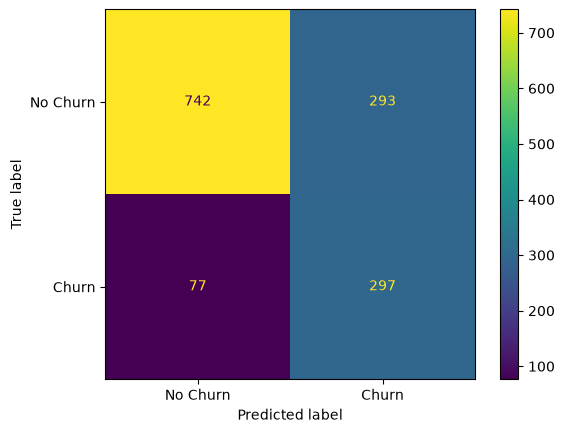

In [21]:
from sklearn.metrics import confusion_matrix ,ConfusionMatrixDisplay
import matplotlib.pylab as plt

cm = confusion_matrix(y_test,Logistic_smote_predict)

print(cm)

disp=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn","Churn"]
)

disp.plot()
plt.show()

In [22]:
import joblib 

joblib.dump(
    Logistic_pip_smote,
    "../models/smote_logistic_final.pkl",
)

['../models/smote_logistic_final.pkl']

In [25]:
# save 
# print(result)
result.to_csv(
    "../results/classification_without_cluster.csv",
    index=False
)